# Hoja de trabajo 2 — Transformers y mecanismos de atención
**CC3092 Deep Learning y Sistemas Inteligentes** · Ian Cumes

Notebook con:
1. Implementación de *scaled dot-product attention* y *multi-head attention* desde cero, verificada contra `F.scaled_dot_product_attention`, `nn.MultiheadAttention` y la capa 0 de BERT.
2. Experimentos de escalamiento ($\sqrt{d_k}$) y de costo computacional ($O(n^2)$).
3. Visualización de atención en **BERT** (`bert-base-uncased`) y **GPT-2** (`gpt2`):
   mapas de calor por cabeza, correferencia de *it*, máscara causal, *attention sinks* y entropía por capa.

In [1]:
import math, time, json, string
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

torch.manual_seed(0)
np.random.seed(0)
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
RES = {}  # resultados numéricos que se usan en el reporte
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
print("torch", torch.__version__)

C:\Users\ianro\OneDrive\Documentos\Uvg\Octavo Semestre\Deep Learning\Hoja de trabajo 2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.14.1+cpu


## 1. Atención desde cero

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

La máscara booleana indica qué posiciones **sí** se pueden atender (misma convención que `F.scaled_dot_product_attention`).

In [2]:
def atencion_escalada(Q, K, V, mask=None):
    # Q: (..., n_q, d_k), K: (..., n_k, d_k), V: (..., n_k, d_v)
    d_k = Q.size(-1)
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    pesos = scores.softmax(dim=-1)
    return pesos @ V, pesos

# Verificación 1: contra la implementación de PyTorch (con y sin máscara causal)
B, H, n, d = 2, 4, 7, 16
Q, K, V = (torch.randn(B, H, n, d) for _ in range(3))
causal = torch.tril(torch.ones(n, n, dtype=torch.bool))

out_nuestra, _ = atencion_escalada(Q, K, V)
out_torch = F.scaled_dot_product_attention(Q, K, V)
out_nuestra_c, w_c = atencion_escalada(Q, K, V, causal)
out_torch_c = F.scaled_dot_product_attention(Q, K, V, is_causal=True)

err1 = (out_nuestra - out_torch).abs().max().item()
err2 = (out_nuestra_c - out_torch_c).abs().max().item()
print(f"sin máscara : error máx = {err1:.2e}")
print(f"causal      : error máx = {err2:.2e}")
print("pesos causales triangulares:", torch.all(w_c.triu(1) == 0).item())
RES["err_sdpa"] = max(err1, err2)

sin máscara : error máx = 3.58e-07
causal      : error máx = 2.38e-07
pesos causales triangulares: True


### Multi-head attention manual vs `nn.MultiheadAttention`
Se copian los pesos de `nn.MultiheadAttention` (`in_proj_weight` = $[W_Q;W_K;W_V]$ y `out_proj`) y se reproduce el *forward*:
proyectar, partir en $h$ cabezas de dimensión $d_{model}/h$, atender en paralelo, concatenar y proyectar.

In [3]:
class MultiHeadManual(nn.Module):
    def __init__(self, d_model, h):
        super().__init__()
        assert d_model % h == 0
        self.h, self.d_k = h, d_model // h
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

    def separar(self, x):  # (B, n, d_model) -> (B, h, n, d_k)
        B, n, _ = x.shape
        return x.view(B, n, self.h, self.d_k).transpose(1, 2)

    def forward(self, q, k, v, mask=None):
        Q, K, V = self.separar(self.W_q(q)), self.separar(self.W_k(k)), self.separar(self.W_v(v))
        out, pesos = atencion_escalada(Q, K, V, mask)
        B, _, n, _ = out.shape
        out = out.transpose(1, 2).reshape(B, n, self.h * self.d_k)  # concatenar cabezas
        return self.W_o(out), pesos

d_model, h = 32, 4
mha = nn.MultiheadAttention(d_model, h, batch_first=True)
manual = MultiHeadManual(d_model, h)
with torch.no_grad():
    Wq, Wk, Wv = mha.in_proj_weight.chunk(3)
    bq, bk, bv = mha.in_proj_bias.chunk(3)
    for lin, W, b in [(manual.W_q, Wq, bq), (manual.W_k, Wk, bk), (manual.W_v, Wv, bv)]:
        lin.weight.copy_(W); lin.bias.copy_(b)
    manual.W_o.weight.copy_(mha.out_proj.weight); manual.W_o.bias.copy_(mha.out_proj.bias)

x = torch.randn(2, 9, d_model)
mask_pt = nn.Transformer.generate_square_subsequent_mask(9)          # float: 0 / -inf
out_pt, w_pt = mha(x, x, x, attn_mask=mask_pt, need_weights=True, average_attn_weights=False)
out_m, w_m = manual(x, x, x, mask=torch.tril(torch.ones(9, 9, dtype=torch.bool)))
print("máscara de generate_square_subsequent_mask(4):\n", nn.Transformer.generate_square_subsequent_mask(4))
err_out = (out_pt - out_m).abs().max().item(); err_w = (w_pt - w_m).abs().max().item()
print(f"error máx salida = {err_out:.2e} | error máx pesos = {err_w:.2e}")
n_params = lambda m: sum(p.numel() for p in m.parameters())
print("parámetros nn.MultiheadAttention:", n_params(mha), "| manual:", n_params(manual))
RES["err_mha"] = max(err_out, err_w)

máscara de generate_square_subsequent_mask(4):
 tensor([[0., -inf, -inf, -inf],
        [0., 0., -inf, -inf],
        [0., 0., 0., -inf],
        [0., 0., 0., 0.]])
error máx salida = 1.19e-07 | error máx pesos = 5.96e-08
parámetros nn.MultiheadAttention: 4224 | manual: 4224


### Número de parámetros: 1 cabeza vs $h$ cabezas
Las proyecciones son siempre $d_{model}\times d_{model}$; partirlas en $h$ cabezas **no cambia** el número de parámetros.

In [4]:
for heads in [1, 2, 4, 8]:
    m = nn.MultiheadAttention(512, heads, batch_first=True)
    print(f"h={heads}: {n_params(m):,} parámetros")

h=1: 1,050,624 parámetros
h=2: 1,050,624 parámetros
h=4: 1,050,624 parámetros
h=8: 1,050,624 parámetros


## 2. ¿Por qué dividir entre $\sqrt{d_k}$? — experimento de escalamiento
Si $q_i, k_i \sim \mathcal{N}(0,1)$ independientes, $q\cdot k=\sum_{i=1}^{d_k} q_i k_i$ tiene media 0 y **varianza $d_k$**.
Sin escalar, los *logits* crecen con $d_k$, la softmax se satura (casi *one-hot*) y su jacobiano $\text{diag}(p)-pp^\top$ tiende a 0.

d_k=    4  Var(q·k)=     3.9  Var(q·k/√d_k)=0.97  max p: 0.419 vs 0.230  ||J||: 0.3230 vs 0.2959
d_k=   16  Var(q·k)=    16.0  Var(q·k/√d_k)=1.00  max p: 0.689 vs 0.244  ||J||: 0.2755 vs 0.3028


d_k=   64  Var(q·k)=    63.1  Var(q·k/√d_k)=0.99  max p: 0.843 vs 0.245  ||J||: 0.1786 vs 0.3041


d_k=  256  Var(q·k)=   261.8  Var(q·k/√d_k)=1.02  max p: 0.920 vs 0.252  ||J||: 0.1014 vs 0.3056


d_k= 1024  Var(q·k)=  1028.5  Var(q·k/√d_k)=1.00  max p: 0.961 vs 0.249  ||J||: 0.0525 vs 0.3050


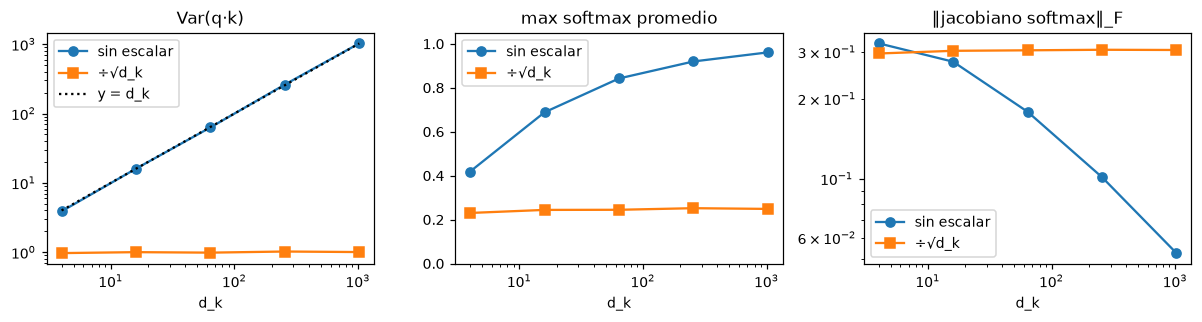

In [5]:
dks = [4, 16, 64, 256, 1024]
n_keys, reps = 16, 2000
var_raw, var_esc, pmax_raw, pmax_esc, grad_raw, grad_esc = [], [], [], [], [], []

def norma_jacobiano(p):  # ||diag(p) - p p^T||_F promedio
    J = torch.diag_embed(p) - p.unsqueeze(-1) * p.unsqueeze(-2)
    return J.flatten(1).norm(dim=1).mean().item()

for dk in dks:
    q = torch.randn(reps, 1, dk); k = torch.randn(reps, n_keys, dk)
    s = (q @ k.transpose(1, 2)).squeeze(1)          # (reps, n_keys)
    s_esc = s / math.sqrt(dk)
    var_raw.append(s.var().item()); var_esc.append(s_esc.var().item())
    p, p_e = s.softmax(-1), s_esc.softmax(-1)
    pmax_raw.append(p.max(-1).values.mean().item()); pmax_esc.append(p_e.max(-1).values.mean().item())
    grad_raw.append(norma_jacobiano(p)); grad_esc.append(norma_jacobiano(p_e))
    print(f"d_k={dk:5d}  Var(q·k)={var_raw[-1]:8.1f}  Var(q·k/√d_k)={var_esc[-1]:.2f}  "
          f"max p: {pmax_raw[-1]:.3f} vs {pmax_esc[-1]:.3f}  ||J||: {grad_raw[-1]:.4f} vs {grad_esc[-1]:.4f}")

RES["escalamiento"] = dict(dks=dks, var_raw=var_raw, var_esc=var_esc, pmax_raw=pmax_raw,
                           pmax_esc=pmax_esc, grad_raw=grad_raw, grad_esc=grad_esc)

fig, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].loglog(dks, var_raw, "o-", label="sin escalar"); ax[0].loglog(dks, var_esc, "s-", label="÷√d_k")
ax[0].loglog(dks, dks, "k:", label="y = d_k"); ax[0].set(title="Var(q·k)", xlabel="d_k"); ax[0].legend()
ax[1].semilogx(dks, pmax_raw, "o-", label="sin escalar"); ax[1].semilogx(dks, pmax_esc, "s-", label="÷√d_k")
ax[1].set(title="max softmax promedio", xlabel="d_k", ylim=(0, 1.05)); ax[1].legend()
ax[2].loglog(dks, grad_raw, "o-", label="sin escalar"); ax[2].loglog(dks, grad_esc, "s-", label="÷√d_k")
ax[2].set(title="‖jacobiano softmax‖_F", xlabel="d_k"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG / "escalamiento.png", dpi=200); plt.show()

## 3. Costo computacional de la self-attention
La matriz $QK^\top$ es $n\times n$: tiempo $O(n^2 d)$ y memoria $O(n^2)$. Se mide el tiempo de la implementación ingenua
(materializa la matriz) frente a `F.scaled_dot_product_attention` (kernel fusionado), y la memoria teórica de la matriz de atención.

n=  128  manual=     2.2 ms  sdpa=     1.3 ms  matriz atención=     0.5 MB
n=  256  manual=     4.5 ms  sdpa=     3.2 ms  matriz atención=     2.0 MB
n=  512  manual=    14.1 ms  sdpa=     6.2 ms  matriz atención=     8.0 MB


n= 1024  manual=    23.6 ms  sdpa=    20.1 ms  matriz atención=    32.0 MB


n= 2048  manual=    75.5 ms  sdpa=    52.8 ms  matriz atención=   128.0 MB


n= 4096  manual=   387.2 ms  sdpa=   178.0 ms  matriz atención=   512.0 MB
pendiente log-log del tiempo (n≥512): 1.60  (≈2 ⇒ cuadrático)
Para n=100,000: 298 GB solo para las matrices de atención de UNA capa (8 cabezas, fp32)


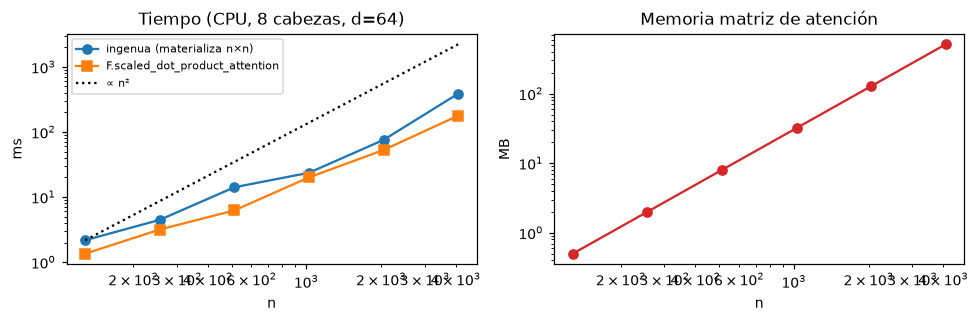

In [6]:
ns = [128, 256, 512, 1024, 2048, 4096]
d, Hh = 64, 8
t_manual, t_sdpa, mem_mb = [], [], []

def cronometrar(f, reps=3):
    f()  # calentamiento
    t0 = time.perf_counter()
    for _ in range(reps): f()
    return (time.perf_counter() - t0) / reps * 1000

with torch.no_grad():
    for n in ns:
        Q, K, V = (torch.randn(1, Hh, n, d) for _ in range(3))
        t_manual.append(cronometrar(lambda: atencion_escalada(Q, K, V)))
        t_sdpa.append(cronometrar(lambda: F.scaled_dot_product_attention(Q, K, V)))
        mem_mb.append(Hh * n * n * 4 / 2**20)   # float32, una capa, batch 1
        print(f"n={n:5d}  manual={t_manual[-1]:8.1f} ms  sdpa={t_sdpa[-1]:8.1f} ms  matriz atención={mem_mb[-1]:8.1f} MB")

pendiente = np.polyfit(np.log(ns[2:]), np.log(t_manual[2:]), 1)[0]
print(f"pendiente log-log del tiempo (n≥512): {pendiente:.2f}  (≈2 ⇒ cuadrático)")
RES["costo"] = dict(ns=ns, t_manual=t_manual, t_sdpa=t_sdpa, mem_mb=mem_mb, pendiente=float(pendiente))
mem_100k = Hh * 100_000**2 * 4 / 2**30
print(f"Para n=100,000: {mem_100k:.0f} GB solo para las matrices de atención de UNA capa (8 cabezas, fp32)")
RES["mem_100k_gb"] = mem_100k

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].loglog(ns, t_manual, "o-", label="ingenua (materializa n×n)")
ax[0].loglog(ns, t_sdpa, "s-", label="F.scaled_dot_product_attention")
ref = np.array(ns, float); ax[0].loglog(ns, t_manual[0] * (ref / ns[0])**2, "k:", label="∝ n²")
ax[0].set(title="Tiempo (CPU, 8 cabezas, d=64)", xlabel="n", ylabel="ms"); ax[0].legend(fontsize=7)
ax[1].loglog(ns, mem_mb, "o-", color="C3"); ax[1].set(title="Memoria matriz de atención", xlabel="n", ylabel="MB")
plt.tight_layout(); plt.savefig(FIG / "costo.png", dpi=200); plt.show()

## 4. Modelos preentrenados: BERT y GPT-2
Se cargan con `output_attentions=True` y `attn_implementation="eager"` (las implementaciones fusionadas SDPA/Flash no devuelven los pesos).
Cada modelo devuelve una tupla con **una atención por capa**, de forma `(batch, cabezas, n, n)`.

In [7]:
tok_bert = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased", output_attentions=True, attn_implementation="eager").eval()
tok_gpt2 = AutoTokenizer.from_pretrained("gpt2")
gpt2 = AutoModel.from_pretrained("gpt2", output_attentions=True, attn_implementation="eager").eval()

def atenciones(model, tok, texto):
    enc = tok(texto, return_tensors="pt")
    with torch.no_grad():
        out = model(**enc, output_attentions=True)
    A = torch.stack(out.attentions)[:, 0].numpy()          # (capas, cabezas, n, n)
    tokens = [t.replace("Ġ", "·") for t in tok.convert_ids_to_tokens(enc["input_ids"][0])]
    return tokens, A, out

frase = "The quick brown fox jumps over the lazy dog, and then it falls asleep."
tok_b, A_b, out_b = atenciones(bert, tok_bert, frase)
tok_g, A_g, out_g = atenciones(gpt2, tok_gpt2, frase)
print("BERT :", len(out_b.attentions), "capas, cada una", tuple(out_b.attentions[0].shape))
print("GPT-2:", len(out_g.attentions), "capas, cada una", tuple(out_g.attentions[0].shape))
print(tok_b); print(tok_g)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   8%|▊         | 15/199 [00:00<00:01, 137.30it/s]

Loading weights:  15%|█▍        | 29/199 [00:00<00:02, 72.66it/s] 

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 517.32it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

Loading weights:   5%|▍         | 7/148 [00:00<00:02, 50.82it/s]

Loading weights:   9%|▉         | 13/148 [00:00<00:03, 34.41it/s]

Loading weights:  11%|█▏        | 17/148 [00:01<00:10, 12.09it/s]

Loading weights: 100%|██████████| 148/148 [00:01<00:00, 128.90it/s]

BERT : 12 capas, cada una (1, 12, 18, 18)
GPT-2: 12 capas, cada una (1, 12, 16, 16)
['[CLS]', 'the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog', ',', 'and', 'then', 'it', 'falls', 'asleep', '.', '[SEP]']
['The', '·quick', '·brown', '·fox', '·jumps', '·over', '·the', '·lazy', '·dog', ',', '·and', '·then', '·it', '·falls', '·asleep', '.']


### Verificación: nuestra atención reproduce la capa 0 de BERT
Se toman los *embeddings* de entrada (`hidden_states[0]`), se aplican las proyecciones `query/key/value` de la capa 0 y nuestra `atencion_escalada`.

In [8]:
enc = tok_bert(frase, return_tensors="pt")
with torch.no_grad():
    hs = bert(**enc, output_hidden_states=True).hidden_states[0]     # (1, n, 768)
    capa0 = bert.encoder.layer[0].attention.self
    sep = lambda t: t.view(1, -1, 12, 64).transpose(1, 2)
    _, w_nuestros = atencion_escalada(sep(capa0.query(hs)), sep(capa0.key(hs)), sep(capa0.value(hs)))
err_bert = (w_nuestros[0].numpy() - A_b[0]).max()
print(f"error máx vs atenciones de BERT capa 0: {abs(err_bert):.2e}")
RES["err_bert_capa0"] = float(abs(err_bert))

error máx vs atenciones de BERT capa 0: 0.00e+00


## 5. Mapas de calor y patrones por cabeza
Para cada cabeza se calcula un puntaje por patrón (promedio de la masa de atención que va a: token anterior, token siguiente,
`[CLS]`/primer token, `[SEP]`, puntuación, el mismo token). Se elige automáticamente la cabeza más representativa de cada patrón
(en capas distintas) y se grafica.

BERT  ('anterior', 3, 5, 0.6700708866119385)
BERT  ('siguiente', 2, 9, 0.9417544007301331)
BERT  ('[CLS]', 1, 6, 0.9046756029129028)
BERT  ('puntuación', 11, 0, 0.8919989466667175)
BERT  ('misma palabra', 4, 3, 0.2263484001159668)
BERT  ('[SEP]', 7, 3, 0.849917471408844)


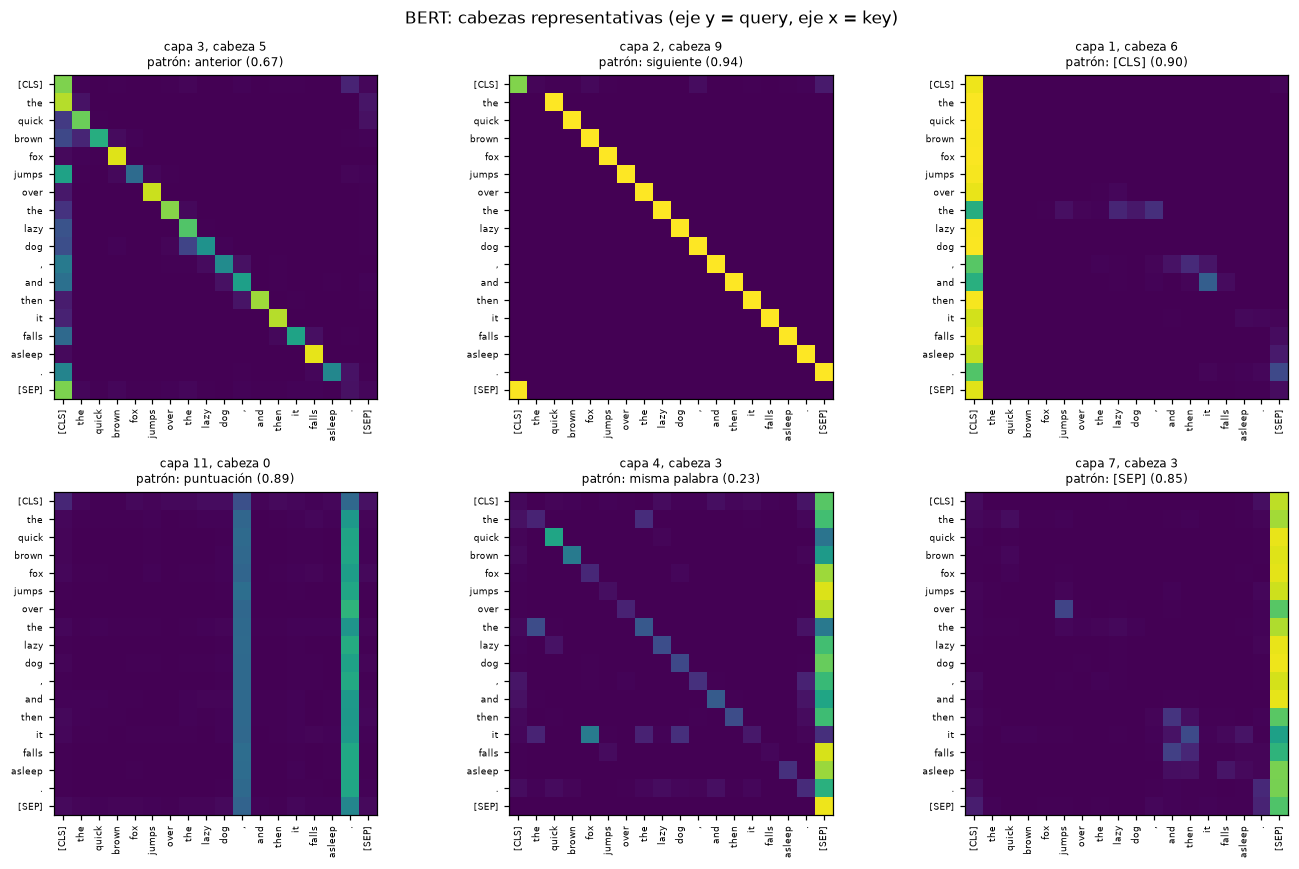

In [9]:
def puntajes_patrones(A, tokens, primero="[CLS]", ultimo="[SEP]"):
    L, H, n, _ = A.shape
    punt = [j for j, t in enumerate(tokens) if t.strip("·") in string.punctuation and t not in ("[CLS]", "[SEP]")]
    idx = np.arange(n)
    pats = {
        "anterior": A[:, :, idx[1:], idx[1:] - 1].mean(-1),
        "siguiente": A[:, :, idx[:-1], idx[:-1] + 1].mean(-1),
        f"{primero}": A[:, :, 1:, 0].mean(-1),
        "puntuación": A[:, :, :, punt].sum(-1).mean(-1),
        "misma palabra": A[:, :, idx, idx].mean(-1),
    }
    if ultimo is not None:
        pats[ultimo] = A[:, :, :, n - 1].mean(-1)
    else:  # modelo causal: no puede ver el token siguiente (siempre 0)
        pats.pop("siguiente")
    return pats

def elegir_cabezas(pats):
    usadas, elegidas = set(), []
    for nombre, M in pats.items():
        for flat in np.argsort(M, axis=None)[::-1]:
            l, h = np.unravel_index(flat, M.shape)
            if l not in usadas:
                usadas.add(l); elegidas.append((nombre, int(l), int(h), float(M[l, h]))); break
    return elegidas

def graficar_cabezas(A, tokens, elegidas, titulo, archivo, ncol=3):
    nrow = math.ceil(len(elegidas) / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 4.0 * nrow))
    for ax, (nombre, l, h, s) in zip(axes.flat, elegidas):
        ax.imshow(A[l, h], cmap="viridis", vmin=0, vmax=1)
        ax.set_xticks(range(len(tokens))); ax.set_xticklabels(tokens, rotation=90, fontsize=6)
        ax.set_yticks(range(len(tokens))); ax.set_yticklabels(tokens, fontsize=6)
        ax.set_title(f"capa {l}, cabeza {h}\npatrón: {nombre} ({s:.2f})", fontsize=8)
    for ax in list(axes.flat)[len(elegidas):]: ax.axis("off")
    fig.suptitle(titulo); plt.tight_layout(); plt.savefig(FIG / archivo, dpi=200); plt.show()

pats_b = puntajes_patrones(A_b, tok_b)
sel_b = elegir_cabezas(pats_b)
for s in sel_b: print("BERT ", s)
graficar_cabezas(A_b, tok_b, sel_b, "BERT: cabezas representativas (eje y = query, eje x = key)", "bert_cabezas.png")

GPT-2 ('anterior', 4, 11, 0.9997974038124084)
GPT-2 ('primer token', 5, 1, 0.9938682317733765)
GPT-2 ('puntuación', 2, 5, 0.16331841051578522)
GPT-2 ('misma palabra', 0, 1, 0.9822044968605042)


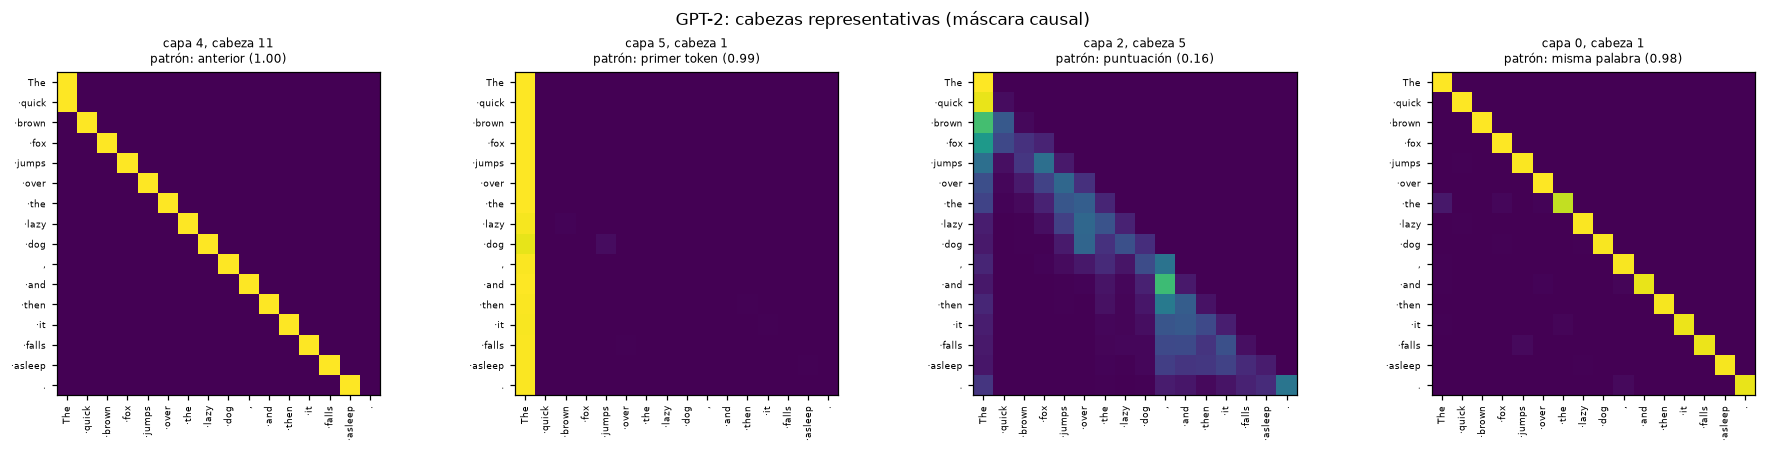

In [10]:
pats_g = puntajes_patrones(A_g, tok_g, primero="primer token", ultimo=None)
sel_g = elegir_cabezas(pats_g)
for s in sel_g: print("GPT-2", s)
graficar_cabezas(A_g, tok_g, sel_g, "GPT-2: cabezas representativas (máscara causal)", "gpt2_cabezas.png", ncol=4)
RES["cabezas_bert"] = sel_b; RES["cabezas_gpt2"] = sel_g

### Resumen de especialización: cabeza dominante de cada capa
Para cada capa se muestra qué patrón alcanza mayor puntaje promedio entre sus cabezas (BERT).

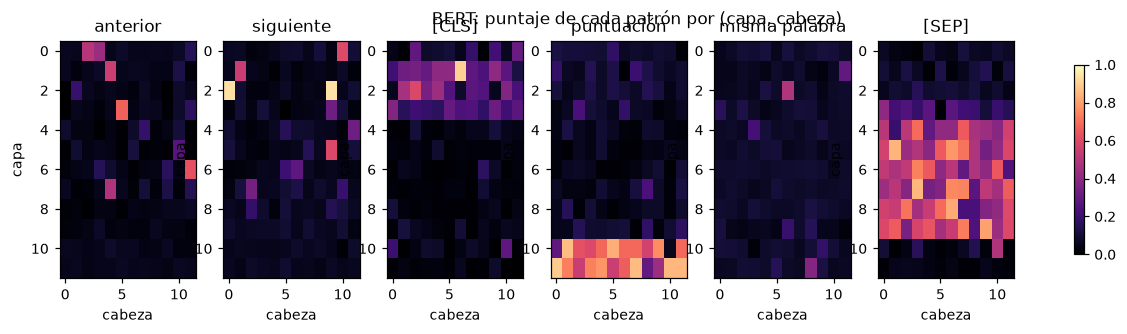

Cabezas de BERT con ≥50% de atención en [CLS]/[SEP]: 54 de 144
por capa: [0 3 4 2 7 8 8 6 7 8 1 0]


In [11]:
fig, axes = plt.subplots(1, len(pats_b), figsize=(14, 2.8))
for ax, (nombre, M) in zip(axes, pats_b.items()):
    im = ax.imshow(M, cmap="magma", vmin=0, vmax=1, aspect="auto")
    ax.set(title=nombre, xlabel="cabeza", ylabel="capa")
fig.colorbar(im, ax=axes, shrink=0.8); plt.suptitle("BERT: puntaje de cada patrón por (capa, cabeza)")
plt.savefig(FIG / "bert_patrones_grid.png", dpi=200, bbox_inches="tight"); plt.show()

# cuántas cabezas son "casi triviales" (≥ 50 % de su masa en [SEP] o [CLS])
triv = ((pats_b["[SEP]"] + pats_b["[CLS]"]) > 0.5)
print(f"Cabezas de BERT con ≥50% de atención en [CLS]/[SEP]: {triv.sum()} de {triv.size}")
print("por capa:", triv.sum(1))
RES["bert_cabezas_sep_cls"] = int(triv.sum())

## 6. Correferencia: ¿a quién atiende *it*?
*The animal didn't cross the street because it was too **tired**.* → *it* = animal
*The animal didn't cross the street because it was too **wide**.* → *it* = street

Para cada cabeza: $\Delta = a(\text{it}\to\text{animal}) - a(\text{it}\to\text{street})$. Se busca una cabeza con $\Delta_{tired}>0$ y $\Delta_{wide}<0$,
maximizando $\Delta_{tired}-\Delta_{wide}$.

cabezas que 'cambian de opinión' correctamente: 22 de 144
capa  6 cabeza 10 | tired: animal=0.284 street=0.067 | wide: animal=0.012 street=0.590
capa  9 cabeza  8 | tired: animal=0.454 street=0.003 | wide: animal=0.023 street=0.045
capa  8 cabeza  4 | tired: animal=0.242 street=0.014 | wide: animal=0.046 street=0.209
capa  4 cabeza 10 | tired: animal=0.333 street=0.095 | wide: animal=0.167 street=0.288
capa  8 cabeza  7 | tired: animal=0.205 street=0.050 | wide: animal=0.061 street=0.194
promedio todas las cabezas  Δ_tired = 0.0682  Δ_wide = 0.0152


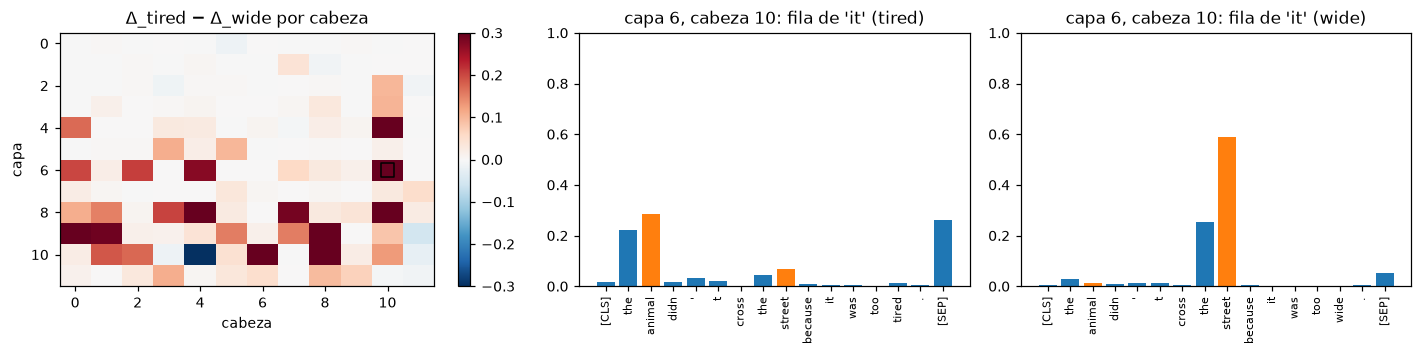

In [12]:
s_tired = "The animal didn't cross the street because it was too tired."
s_wide  = "The animal didn't cross the street because it was too wide."
tk_t, A_t, _ = atenciones(bert, tok_bert, s_tired)
tk_w, A_w, _ = atenciones(bert, tok_bert, s_wide)
i_it, i_an, i_st = tk_t.index("it"), tk_t.index("animal"), tk_t.index("street")
assert tk_w.index("it") == i_it

d_t = A_t[:, :, i_it, i_an] - A_t[:, :, i_it, i_st]
d_w = A_w[:, :, i_it, i_an] - A_w[:, :, i_it, i_st]
score = np.where((d_t > 0) & (d_w < 0), d_t - d_w, np.nan)
print(f"cabezas que 'cambian de opinión' correctamente: {np.isfinite(score).sum()} de {score.size}")
top = np.argsort(np.nan_to_num(score, nan=-1), axis=None)[::-1][:5]
filas = []
for f in top:
    l, h = np.unravel_index(f, score.shape)
    filas.append(dict(capa=int(l), cabeza=int(h),
                      tired_animal=float(A_t[l, h, i_it, i_an]), tired_street=float(A_t[l, h, i_it, i_st]),
                      wide_animal=float(A_w[l, h, i_it, i_an]), wide_street=float(A_w[l, h, i_it, i_st])))
    print(f"capa {l:2d} cabeza {h:2d} | tired: animal={A_t[l,h,i_it,i_an]:.3f} street={A_t[l,h,i_it,i_st]:.3f} "
          f"| wide: animal={A_w[l,h,i_it,i_an]:.3f} street={A_w[l,h,i_it,i_st]:.3f}")
RES["coref"] = dict(n_cabezas=int(np.isfinite(score).sum()), top=filas)
# además: promedio sobre todas las cabezas (¿el modelo en conjunto distingue?)
print("promedio todas las cabezas  Δ_tired = %.4f  Δ_wide = %.4f" % (d_t.mean(), d_w.mean()))
RES["coref"]["delta_prom"] = [float(d_t.mean()), float(d_w.mean())]

l, h = filas[0]["capa"], filas[0]["cabeza"]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3), gridspec_kw={"width_ratios": [1.2, 1, 1]})
im = ax[0].imshow(d_t - d_w, cmap="RdBu_r", vmin=-0.3, vmax=0.3, aspect="auto")
ax[0].scatter([h], [l], marker="s", s=80, facecolors="none", edgecolors="k")
ax[0].set(title="Δ_tired − Δ_wide por cabeza", xlabel="cabeza", ylabel="capa"); fig.colorbar(im, ax=ax[0])
for a, A_, tk, nombre in [(ax[1], A_t, tk_t, "tired"), (ax[2], A_w, tk_w, "wide")]:
    cols = ["C1" if t in ("animal", "street") else "C0" for t in tk]
    a.bar(range(len(tk)), A_[l, h, i_it], color=cols)
    a.set_xticks(range(len(tk))); a.set_xticklabels(tk, rotation=90, fontsize=7)
    a.set(title=f"capa {l}, cabeza {h}: fila de 'it' ({nombre})", ylim=(0, 1))
plt.tight_layout(); plt.savefig(FIG / "bert_coref.png", dpi=200); plt.show()

## 7. GPT-2: máscara causal y *attention sinks*
Se usa un texto más largo para que la proporción sea estable.

n = 44 tokens | máximo peso por encima de la diagonal (todas las capas/cabezas): 0.00e+00
¿filas suman 1? True
capa  0: GPT-2 primer token = 0.103 | BERT [CLS] = 0.074  [SEP] = 0.023
capa  1: GPT-2 primer token = 0.217 | BERT [CLS] = 0.273  [SEP] = 0.036
capa  2: GPT-2 primer token = 0.223 | BERT [CLS] = 0.243  [SEP] = 0.059
capa  3: GPT-2 primer token = 0.468 | BERT [CLS] = 0.206  [SEP] = 0.172
capa  4: GPT-2 primer token = 0.486 | BERT [CLS] = 0.048  [SEP] = 0.449
capa  5: GPT-2 primer token = 0.680 | BERT [CLS] = 0.022  [SEP] = 0.558
capa  6: GPT-2 primer token = 0.639 | BERT [CLS] = 0.020  [SEP] = 0.524
capa  7: GPT-2 primer token = 0.748 | BERT [CLS] = 0.014  [SEP] = 0.563
capa  8: GPT-2 primer token = 0.638 | BERT [CLS] = 0.020  [SEP] = 0.524
capa  9: GPT-2 primer token = 0.741 | BERT [CLS] = 0.032  [SEP] = 0.426
capa 10: GPT-2 primer token = 0.740 | BERT [CLS] = 0.036  [SEP] = 0.049
capa 11: GPT-2 primer token = 0.579 | BERT [CLS] = 0.012  [SEP] = 0.019
referencia uniforme GPT-2

primer token distinto ('Yesterday'): media capas 2-11 = 0.587 vs original 0.594


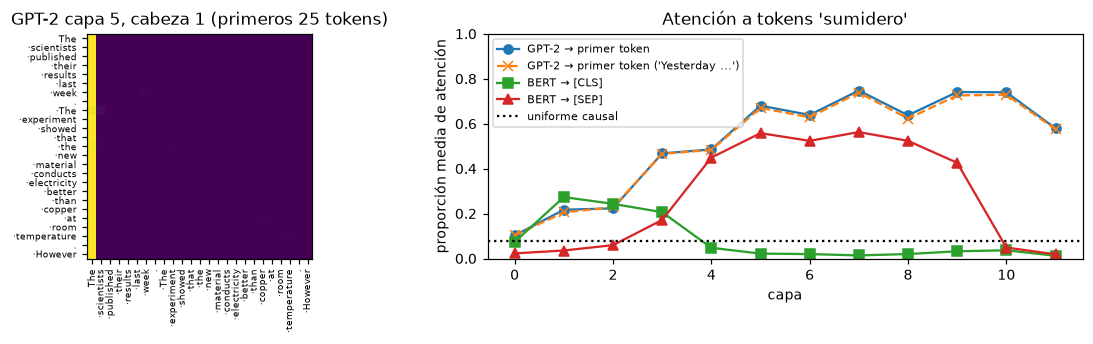

In [13]:
texto_largo = ("The scientists published their results last week. The experiment showed that the new material "
               "conducts electricity better than copper at room temperature. However, other groups have not yet "
               "reproduced the findings, so many researchers remain skeptical about the claims.")
tk_gl, A_gl, _ = atenciones(gpt2, tok_gpt2, texto_largo)
L, H, n, _ = A_gl.shape
sup = np.triu(np.ones((n, n), bool), k=1)
max_sup = A_gl[:, :, sup].max()
print(f"n = {n} tokens | máximo peso por encima de la diagonal (todas las capas/cabezas): {max_sup:.2e}")
print("¿filas suman 1?", np.allclose(A_gl.sum(-1), 1, atol=1e-5))
RES["gpt2_max_superior"] = float(max_sup)

# proporción de atención al primer token (excluyendo la query 0, que solo puede verse a sí misma)
prop_primero = A_gl[:, :, 1:, 0].mean(axis=(1, 2))
# referencia: si la atención fuera uniforme sobre las posiciones visibles, el token 0 recibiría 1/(i+1)
ref_uniforme = np.mean(1 / (np.arange(1, n) + 1))
# para BERT: masa a [CLS] y a [SEP] por capa con el mismo texto
tk_bl, A_bl, _ = atenciones(bert, tok_bert, texto_largo)
cls_b = A_bl[:, :, :, 0].mean(axis=(1, 2)); sep_b = A_bl[:, :, :, -1].mean(axis=(1, 2))
for l in range(L):
    print(f"capa {l:2d}: GPT-2 primer token = {prop_primero[l]:.3f} | BERT [CLS] = {cls_b[l]:.3f}  [SEP] = {sep_b[l]:.3f}")
print(f"referencia uniforme GPT-2: {ref_uniforme:.3f}")
RES["gpt2_primer_token"] = prop_primero.tolist(); RES["ref_uniforme"] = float(ref_uniforme)
RES["bert_cls"] = cls_b.tolist(); RES["bert_sep"] = sep_b.tolist()

# ¿Es por la posición o por el contenido? Se repite anteponiendo otro token inicial
alt = "Yesterday " + texto_largo[0].lower() + texto_largo[1:]
_, A_alt, _ = atenciones(gpt2, tok_gpt2, alt)
prop_alt = A_alt[:, :, 1:, 0].mean(axis=(1, 2))
print("primer token distinto ('Yesterday'): media capas 2-11 =", prop_alt[2:].mean().round(3),
      "vs original", prop_primero[2:].mean().round(3))
RES["gpt2_primer_token_alt"] = prop_alt.tolist()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].imshow(A_gl[5, 1][:25, :25], cmap="viridis"); ax[0].set_title("GPT-2 capa 5, cabeza 1 (primeros 25 tokens)")
ax[0].set_xticks(range(25)); ax[0].set_xticklabels(tk_gl[:25], rotation=90, fontsize=6)
ax[0].set_yticks(range(25)); ax[0].set_yticklabels(tk_gl[:25], fontsize=6)
ax[1].plot(prop_primero, "o-", label="GPT-2 → primer token")
ax[1].plot(prop_alt, "x--", label="GPT-2 → primer token ('Yesterday ...')")
ax[1].plot(cls_b, "s-", label="BERT → [CLS]"); ax[1].plot(sep_b, "^-", label="BERT → [SEP]")
ax[1].axhline(ref_uniforme, color="k", ls=":", label="uniforme causal")
ax[1].set(xlabel="capa", ylabel="proporción media de atención", title="Atención a tokens 'sumidero'", ylim=(0, 1))
ax[1].legend(fontsize=7); plt.tight_layout(); plt.savefig(FIG / "gpt2_sinks.png", dpi=200); plt.show()

## 8. Entropía de la atención por capa
$H_i = -\sum_j a_{ij}\log a_{ij}$ (en nats). En GPT-2 la fila $i$ solo ve $i+1$ posiciones, así que su máximo es $\log(i+1)$;
por eso también se reporta la **entropía normalizada** $H_i/\log(\#\text{keys visibles})\in[0,1]$ (en BERT se divide entre $\log n$).
Se promedia sobre varias oraciones, cabezas y posiciones.

capa  0: BERT H=2.296 (norm 0.766) | GPT-2 H=1.435 (norm 0.665)
capa  1: BERT H=1.833 (norm 0.610) | GPT-2 H=1.612 (norm 0.723)
capa  2: BERT H=1.591 (norm 0.529) | GPT-2 H=1.431 (norm 0.660)
capa  3: BERT H=1.769 (norm 0.590) | GPT-2 H=1.122 (norm 0.522)
capa  4: BERT H=1.522 (norm 0.508) | GPT-2 H=0.964 (norm 0.441)
capa  5: BERT H=1.226 (norm 0.411) | GPT-2 H=0.865 (norm 0.396)
capa  6: BERT H=1.295 (norm 0.435) | GPT-2 H=0.981 (norm 0.448)
capa  7: BERT H=1.226 (norm 0.414) | GPT-2 H=0.744 (norm 0.334)
capa  8: BERT H=1.469 (norm 0.493) | GPT-2 H=0.927 (norm 0.415)
capa  9: BERT H=1.672 (norm 0.559) | GPT-2 H=0.713 (norm 0.321)
capa 10: BERT H=1.604 (norm 0.534) | GPT-2 H=0.691 (norm 0.307)
capa 11: BERT H=1.672 (norm 0.556) | GPT-2 H=1.005 (norm 0.448)


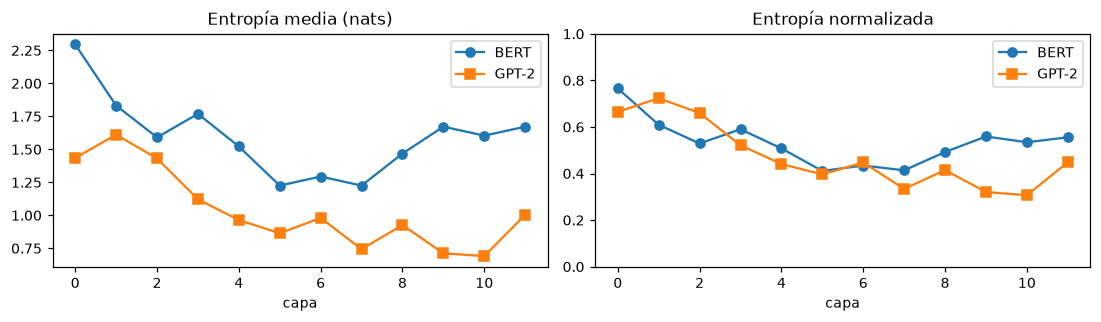

In [14]:
oraciones = [frase, s_tired, s_wide, texto_largo,
             "Attention mechanisms allow neural networks to focus on the most relevant parts of the input.",
             "She bought apples, oranges and bananas at the market before going home."]

def entropia_por_capa(model, tok, causal):
    Hs, Hn = [], []
    for s in oraciones:
        _, A, _ = atenciones(model, tok, s)
        ent = -(A * np.log(A + 1e-12)).sum(-1)               # (L, H, n)
        n = A.shape[-1]
        visibles = np.arange(1, n + 1) if causal else np.full(n, n)
        ent, vis = (ent[:, :, 1:], visibles[1:]) if causal else (ent, visibles)
        Hs.append(ent.mean(axis=(1, 2))); Hn.append((ent / np.log(vis)).mean(axis=(1, 2)))
    return np.mean(Hs, 0), np.mean(Hn, 0)

Hb, Hb_n = entropia_por_capa(bert, tok_bert, causal=False)
Hg, Hg_n = entropia_por_capa(gpt2, tok_gpt2, causal=True)
for l in range(12):
    print(f"capa {l:2d}: BERT H={Hb[l]:.3f} (norm {Hb_n[l]:.3f}) | GPT-2 H={Hg[l]:.3f} (norm {Hg_n[l]:.3f})")
RES["entropia"] = dict(bert=Hb.tolist(), bert_n=Hb_n.tolist(), gpt2=Hg.tolist(), gpt2_n=Hg_n.tolist())

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(Hb, "o-", label="BERT"); ax[0].plot(Hg, "s-", label="GPT-2")
ax[0].set(title="Entropía media (nats)", xlabel="capa"); ax[0].legend()
ax[1].plot(Hb_n, "o-", label="BERT"); ax[1].plot(Hg_n, "s-", label="GPT-2")
ax[1].set(title="Entropía normalizada", xlabel="capa", ylim=(0, 1)); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "entropia.png", dpi=200); plt.show()

## 9. (Opcional) bertviz
Vista interactiva de las cabezas (solo se renderiza en Jupyter con JavaScript habilitado).

In [15]:
try:
    from bertviz import head_view
    tk_v, _, out_v = atenciones(bert, tok_bert, s_tired)
    head_view(out_v.attentions, tk_v)
except Exception as e:
    print("bertviz no disponible:", e)

<IPython.core.display.Javascript object>

In [16]:
def a_json(o):
    if isinstance(o, (np.floating, np.integer)): return o.item()
    raise TypeError(type(o))
Path("resultados.json").write_text(json.dumps(RES, indent=1, default=a_json), encoding="utf-8")
print("resultados guardados en resultados.json")

resultados guardados en resultados.json


## Conclusiones
- La implementación propia coincide con PyTorch y con BERT hasta error numérico de punto flotante.
- El factor $1/\sqrt{d_k}$ mantiene la varianza de los *logits* en ~1 independientemente de $d_k$ y evita que la softmax se sature y anule sus gradientes.
- El costo de la atención estándar crece cuadráticamente con $n$ en tiempo y memoria.
- Las cabezas se especializan (token anterior/siguiente, puntuación, `[SEP]`), pero muchas concentran casi toda su masa en `[SEP]`/`[CLS]` o en el primer token (GPT-2): *attention sinks* que funcionan como un "no-op".
- Hay cabezas de BERT que resuelven la correferencia de *it* según el contexto, aunque el efecto es pequeño y no prueba por sí solo que la decisión del modelo se base en esa cabeza.